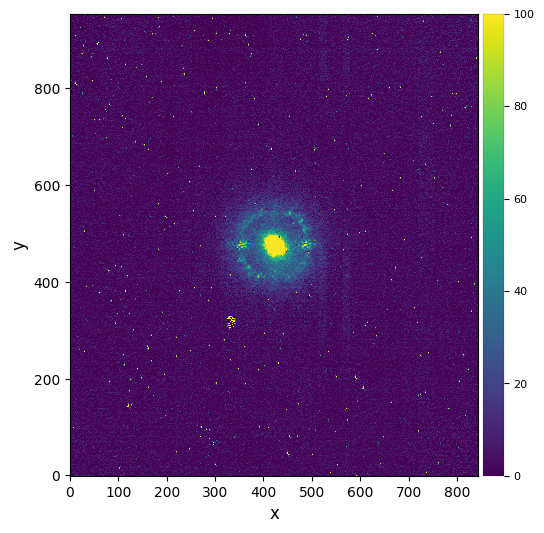

In [2]:
from astropy.io import fits
from hciplot import plot_frames, plot_cubes
import numpy as np

cube = '/data/beegfs/astro-storage/groups/beuther/pasteimle/hd11397_final_data_new/LEFT_CUBE.fits'

data = np.nan_to_num(fits.getdata(cube)[:,20:-20,20:-20])
plot_frames(data[0], vmin = 0 , vmax = 100)

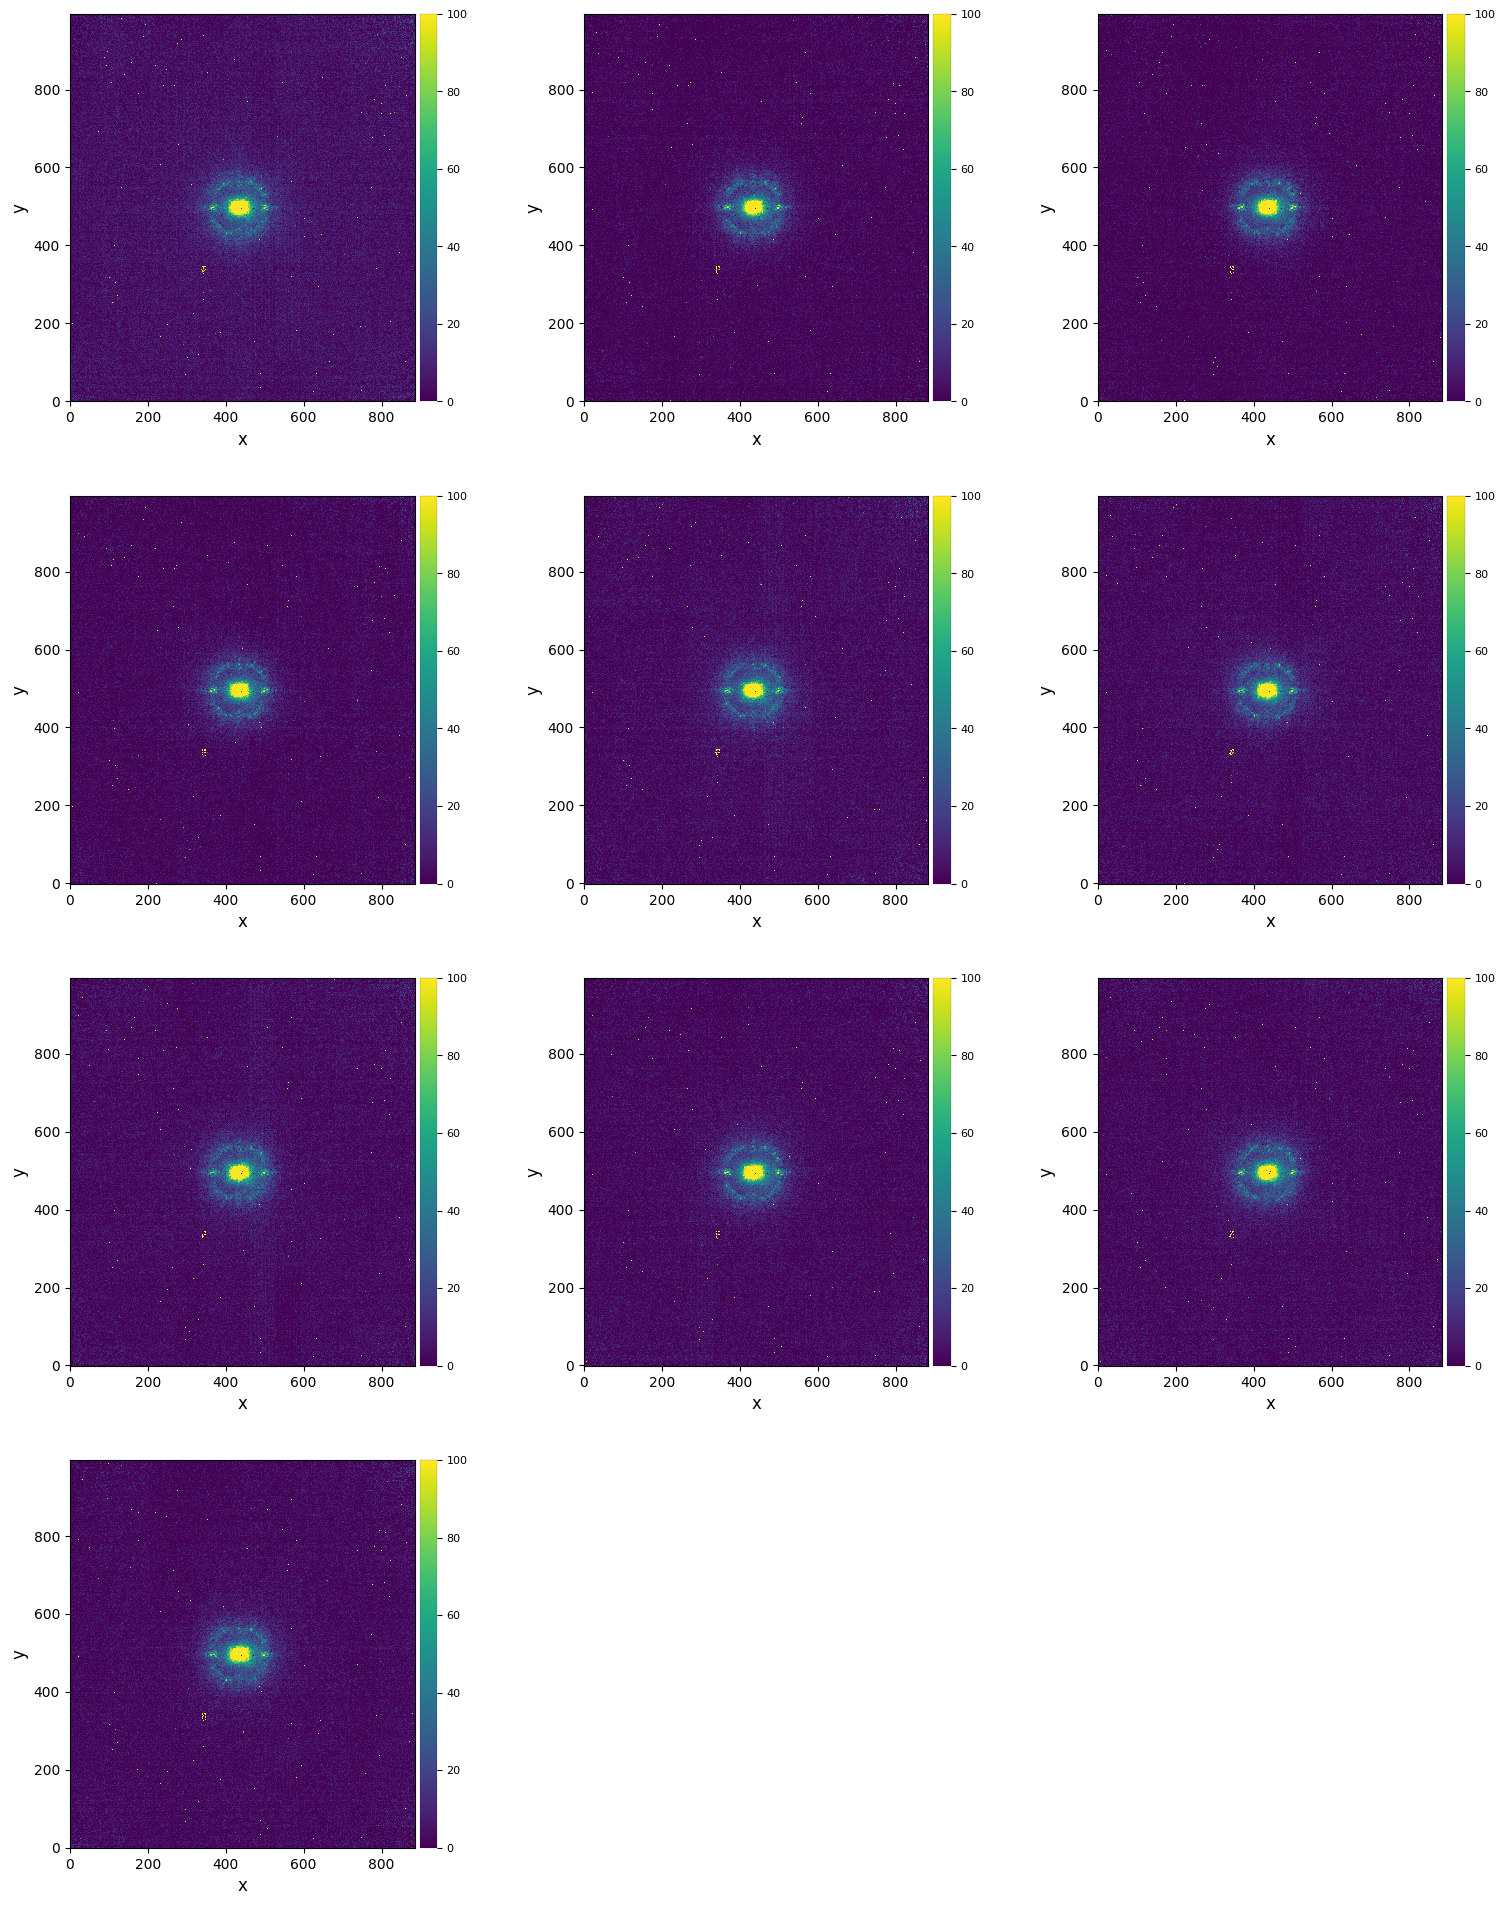

In [3]:
from glob import glob 
cube = glob('/data/beegfs/astro-storage/groups/beuther/pasteimle/hd11397_processed_data_new/SCIENCE_LEFT*.fits')[1]

data = np.nan_to_num(fits.getdata(cube))
plot_frames(data, vmin = 0 , vmax = 100, rows = 4)

In [10]:
from vip_hci.preproc import cube_fix_badpix_isolated
cube_sigcorr = data
cube_sigcorr, bpm_mask = cube_fix_badpix_isolated(cube_sigcorr[:3], sigma_clip= 5, num_neig=29, size=9, 
                                                frame_by_frame=False, mad=True, verbose=True, 
                                                full_output=True, protect_mask= 80) 

# cube_sigcorr, bpm_mask_tmp = cube_fix_badpix_isolated(cube_sigcorr, bpm_mask=bpm_mask, correct_only=False, 
#                                                     sigma_clip=5, num_neig=9, size=9, frame_by_frame=True,
#                                                     mad=True, verbose=True, full_output=True)




――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Starting time: 2025-04-23 10:36:05
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Done replacing 18762 bad pixels using the median of neighbors
(i.e. 6254 static bad pixels per channel))
Running time:  0:25:54.427644
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――


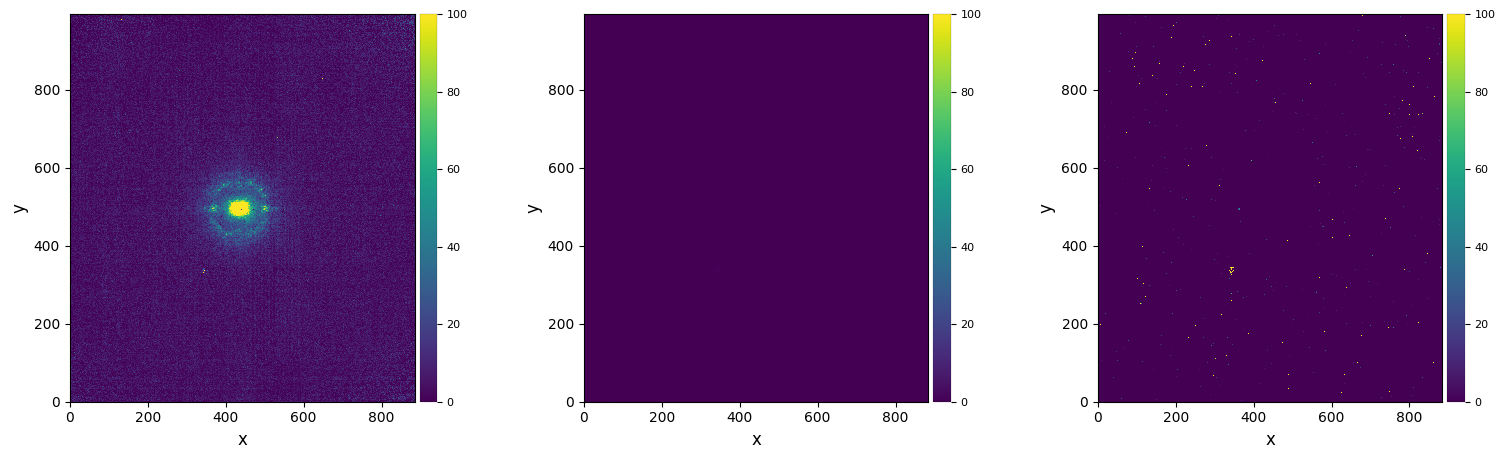

In [12]:
plot_frames([cube_sigcorr[0], bpm_mask, data[0]-cube_sigcorr[0] ], vmin = 0 , vmax = 100)

In [13]:
cube_sigcorr, bpm_mask = cube_fix_badpix_isolated(cube_sigcorr[:3], sigma_clip= 5, num_neig=29, size=9, 
                                                frame_by_frame=True, mad=True, verbose=True, 
                                                full_output=True, protect_mask= 80, nproc=4) 

――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Starting time: 2025-04-23 11:52:23
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Cleaning frames using ADACS' multiprocessing approach
Done replacing 1445 bad pixels using the median of neighbors
Running time:  0:26:19.067447
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――


In [ ]:
from vip_hci.preproc import cube_fix_badpix_annuli, cube_fix_badpix_clump
cube_sigcorr, bpm_mask = cube_fix_badpix_annuli(cube_sigcorr[:3], sigma_clip= 5
                                                frame_by_frame=False, mad=True, verbose=True, 
                                                full_output=True, protect_mask= 100) 

(3, 995, 885)

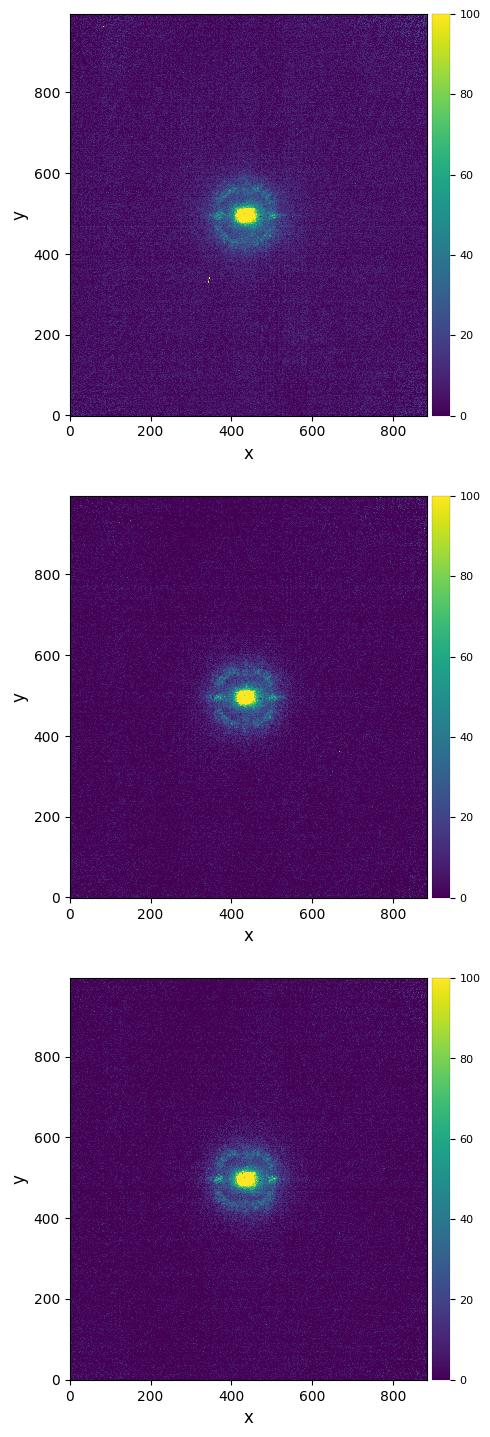

In [7]:
plot_frames(cube_sigcorr, vmin = 0 , vmax = 100, rows = 4)

In [13]:
from SIRP.misc import make_dark_DF
import os 
from os.path import join
from astropy.io import fits
import numpy as np

star_parent_dir = os.path.join('/data/beegfs/astro-storage/groups/beuther/pasteimle/all_raw_data/', 'DARK', 'IRDIS')
all_obs_nights = os.listdir(star_parent_dir)

for obs_night in all_obs_nights:
    obs_night_parent_dir = join(star_parent_dir,obs_night)
    obs_run = obs_night[:-3]
    filters = os.listdir(obs_night_parent_dir)

    for filter_name in filters:
        pass


In [ ]:
from vip_hci.preproc import cube_fix_badpix_isolated
from numpy import nanmedian

def make_bad_pix_mask(obs_night,filter_name):

    DARK_DF = make_dark_DF('/data/beegfs/astro-storage/groups/beuther/pasteimle/all_raw_data/')
    darks = DARK_DF[(DARK_DF['obs_run']== obs_run) & (DARK_DF['filter']== filter_name)]['filepath']


    all_dark_files = []
    
    for file in darks:
        hdul = fits.open(file)
        cube = hdul[0].data

        for image in cube:

            all_dark_files.append(image)
        hdul.close()

    all_dark_files = np.array(all_dark_files)

    coef = 5

    sky = nanmedian(all_dark_files, axis = 0)

    med = nanmedian(sky)

    sigma = 1.4826 * nanmedian(np.abs(sky - med))
    # the 1.4826 converts the Median Absolute Deviation
    # to the standard deviation for a Normal distribution

    print("Sigma: " + str(sigma) + ", median: " + str(med))

    # Creates a tuple with the x-y positions of the dead pixels
    deadpix = np.where(sky < med - sigma * coef)

    # Creates a tuple with the x-y positions of the dead pixels
    hotpix = np.where(sky > med + sigma * coef)


    badpix = tuple(np.append(np.array(deadpix), np.array(hotpix), axis=1))

    bpx_mask = np.zeros(sky.shape)
    for y,x in zip(badpix[0], badpix[1]):
        bpx_mask[y,x] = 1


    return badpix
    

    cube_sigcorr, bpm_mask = cube_fix_badpix_isolated(all_dark_files, sigma_clip=5, num_neig=9, size=9, 
                                                        frame_by_frame=False, mad=True, verbose=True, 
                                                        full_output=True) 
    
    return cube_sigcorr, bpm_mask,all_dark_files
    print(all_dark_files.shape)


badpix, comments, sky = make_bad_pix_mask('2022-10-14', 'DB_H23')

#cube_sigcorr, bpm_mask,all_dark_files = make_bad_pix_mask('2022-10-14', 'DB_H23')

Sigma: 0.9266249999999999, median: -0.125
[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]


In [41]:
badpix[0].shape

(4096,)

In [ ]:
dummy = np.zeros(sky.shape)
for y,x in zip(badpix[0], badpix[1]):
    dummy[y,x] = 1

In [40]:
from hciplot import plot_frames

#plot_frames(all_dark_files[0], cube_sigcorr[0], bpm_mask[0])
plot_frames([sky, badpix[0], badpix[1]])


ValueError: `data` must be a frame (2d array) or tuple of frames

In [ ]:
def clean_bp(badpix, cub_in):
    
    # (deadpix, hotpix, negativepix, cub_in):
    cub_in[:, badpix[0], badpix[1]] = np.NaN
    for f in range(cub_in.shape[0]):
        for j in range(len(badpix[0])):
            y = badpix[0][j]
            x = badpix[1][j]

            if y == cube.shape[1] - 1:  # At the image edge !!!
                if x == cube.shape[2] - 1:  # In a corner
                    cub_in[f, y, x] = nanmedian([
                            cub_in[f, y - 1, x - 1], cub_in[f, y - 1, x],
                            cub_in[f, y, x - 1]
                    ])
                elif x == 0:
                    cub_in[f, y, x] = nanmedian([
                            cub_in[f, y - 1, x], cub_in[f, y - 1, x + 1],
                            cub_in[f, y, x + 1]
                    ])
                else:  # Along the edge
                    cub_in[f, y, x] = nanmedian([
                            cub_in[f, y - 1, x - 1], cub_in[f, y - 1, x],
                            cub_in[f, y - 1, x + 1], cub_in[f, y, x - 1],
                            cub_in[f, y, x + 1]
                    ])
            elif y == 0:  # At the image edge !!!
                if x == cube.shape[2] - 1:  # In a corner
                    cub_in[f, y, x] = nanmedian([
                            cub_in[f, y, x - 1], cub_in[f, y + 1, x - 1],
                            cub_in[f, y + 1, x]
                    ])
                elif x == 0:  # In a corner
                    cub_in[f, y, x] = nanmedian([
                            cub_in[f, y, x + 1], cub_in[f, y + 1, x],
                            cub_in[f, y + 1, x + 1]
                    ])
                else:  # Along the edge
                    cub_in[f, y, x] = nanmedian([
                            cub_in[f, y, x - 1], cub_in[f, y, x + 1],
                            cub_in[f, y + 1, x - 1], cub_in[f, y + 1, x],
                            cub_in[f, y + 1, x + 1]
                    ])
            elif x == 0:  # Along the edge
                cub_in[f, y, x] = nanmedian([
                        cub_in[f, y - 1, x], cub_in[f, y - 1, x + 1],
                        cub_in[f, y, x + 1], cub_in[f, y + 1,
                                                    x], cub_in[f, y + 1, x + 1]
                ])
            elif x == cub_in.shape[2] - 1:  # Along the edge
                cub_in[f, y, x] = nanmedian([
                        cub_in[f, y - 1, x - 1], cub_in[f, y - 1, x],
                        cub_in[f, y, x - 1], cub_in[f, y + 1,
                                                    x - 1], cub_in[f, y + 1, x]
                ])
            else:  # Usual case, not on an edge
                cub_in[f, y, x] = nanmedian([
                        cub_in[f, y - 1, x - 1], cub_in[f, y - 1, x],
                        cub_in[f, y - 1, x + 1], cub_in[f, y, x - 1],
                        cub_in[f, y, x + 1], cub_in[f, y + 1, x - 1],
                        cub_in[f, y + 1, x], cub_in[f, y + 1, x + 1]
                ])
    return cub_in

removed = clean_bp()

0

In [28]:
comments

['Found 5992 = 0.2857208251953125% dead, and 37203 = 1.773977279663086% hot pixels.']